In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the public Superstore dataset
url = "https://raw.githubusercontent.com/curran/data/gh-pages/superstoreSales/superstoreSales.csv"
df = pd.read_csv(url, encoding="cp1252")

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Map the dataset's column names to the practical's names
rename_map = {}

if "sales_amount" not in df.columns and "sales" in df.columns:
    rename_map["sales"] = "sales_amount"

if "product_category" not in df.columns and "category" in df.columns:
    rename_map["category"] = "product_category"

df = df.rename(columns=rename_map)

print("First rows:")
print(df.head())

First rows:
   row_id  order_id  order_date order_priority  order_quantity  sales_amount  \
0       1         3  10/13/2010            Low               6      261.5400   
1      49       293   10/1/2012           High              49    10123.0200   
2      50       293   10/1/2012           High              27      244.5700   
3      80       483   7/10/2011           High              30     4965.7595   
4      85       515   8/28/2010  Not Specified              19      394.2700   

   discount       ship_mode   profit  unit_price  ...       customer_name  \
0      0.04     Regular Air  -213.25       38.94  ...  Muhammed MacIntyre   
1      0.07  Delivery Truck   457.81      208.16  ...        Barry French   
2      0.01     Regular Air    46.71        8.69  ...        Barry French   
3      0.08     Regular Air  1198.97      195.99  ...       Clay Rozendal   
4      0.08     Regular Air    30.94       21.78  ...      Carlos Soltero   

  province   region customer_segment product

In [2]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   row_id                8399 non-null   int64  
 1   order_id              8399 non-null   int64  
 2   order_date            8399 non-null   str    
 3   order_priority        8399 non-null   str    
 4   order_quantity        8399 non-null   int64  
 5   sales_amount          8399 non-null   float64
 6   discount              8399 non-null   float64
 7   ship_mode             8399 non-null   str    
 8   profit                8399 non-null   float64
 9   unit_price            8399 non-null   float64
 10  shipping_cost         8399 non-null   float64
 11  customer_name         8399 non-null   str    
 12  province              8399 non-null   str    
 13  region                8399 non-null   str    
 14  customer_segment      8399 non-null   str    
 15  product_ca

In [3]:
print("\nMissing values:")
print(df.isna().sum())


Missing values:
row_id                   0
order_id                 0
order_date               0
order_priority           0
order_quantity           0
sales_amount             0
discount                 0
ship_mode                0
profit                   0
unit_price               0
shipping_cost            0
customer_name            0
province                 0
region                   0
customer_segment         0
product_category         0
product_sub_category     0
product_name             0
product_container        0
product_base_margin     63
ship_date                0
dtype: int64


In [4]:
# Check that the required fields are present
required_columns = ["region", "sales_amount", "product_category"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Clean and convert values
df["sales_amount"] = pd.to_numeric(df["sales_amount"], errors="coerce")
df["region"] = df["region"].astype("string").str.strip().replace("", pd.NA)
df["product_category"] = (
    df["product_category"].astype("string").str.strip().replace("", pd.NA)
)

df = df.dropna(subset=required_columns).copy()

# Total sales by region and highest-performing region
region_sales = (
    df.groupby("region")["sales_amount"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRegional sales:")
print(region_sales)


Regional sales:
region
West                     3.597549e+06
Ontario                  3.063212e+06
Prarie                   2.837305e+06
Atlantic                 2.014248e+06
Quebec                   1.510195e+06
Yukon                    9.758674e+05
Northwest Territories    8.008473e+05
Nunavut                  1.163765e+05
Name: sales_amount, dtype: float64



Top region: West Total: 3597549.2755


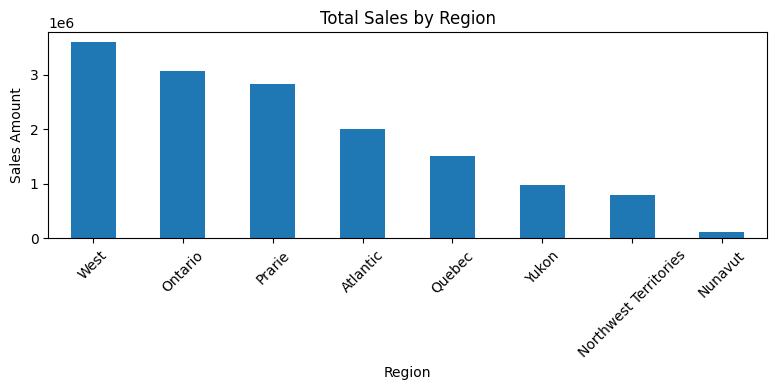

In [5]:
if not region_sales.empty:
    print(
        "\nTop region:",
        region_sales.idxmax(),
        "Total:",
        region_sales.max()
    )

    ax = region_sales.plot(
        kind="bar",
        figsize=(8, 4),
        title="Total Sales by Region"
    )
    ax.set_xlabel("Region")
    ax.set_ylabel("Sales Amount")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [6]:
# Region-by-category pivot table
pivot = df.pivot_table(
    index="region",
    columns="product_category",
    values="sales_amount",
    aggfunc="sum",
    fill_value=0
)

print("\nSales by region and product category:")
print(pivot)


Sales by region and product category:
product_category         Furniture  Office Supplies    Technology
region                                                           
Atlantic                708726.782        478464.42  8.270570e+05
Northwest Territories   282837.908        216848.93  3.011605e+05
Nunavut                  43545.614         38615.47  3.421540e+04
Ontario                1109617.500        927431.25  1.026164e+06
Prarie                  919191.126        720090.43  1.198023e+06
Quebec                  605784.144        351822.68  5.525883e+05
West                   1172989.394        797510.76  1.627049e+06
Yukon                   335898.074        221978.16  4.179911e+05


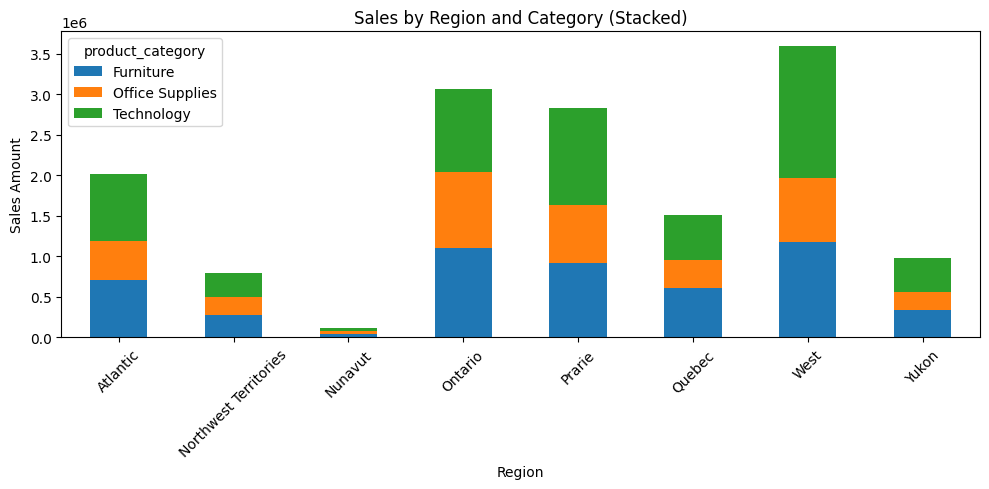

In [7]:
# Stacked bar chart
ax = pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    title="Sales by Region and Category (Stacked)"
)
ax.set_xlabel("Region")
ax.set_ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

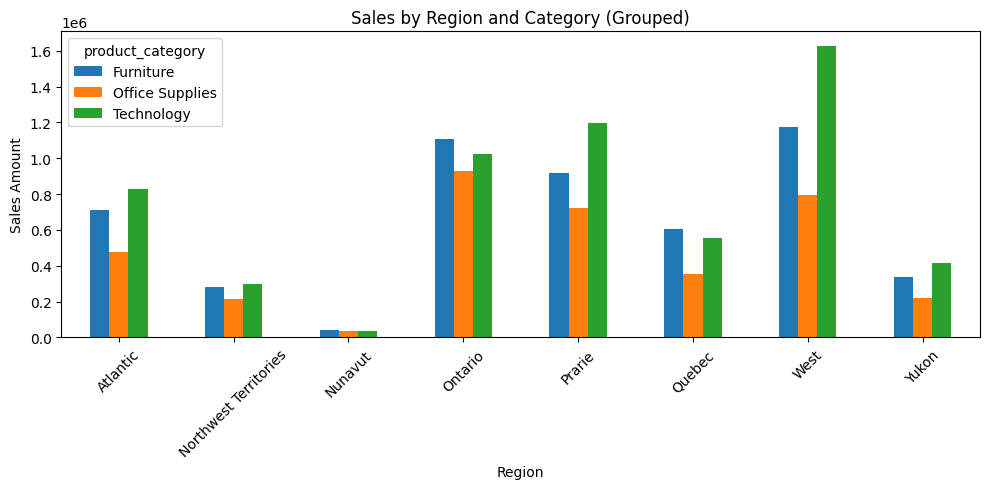

In [8]:
# Grouped bar chart
ax = pivot.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 5),
    title="Sales by Region and Category (Grouped)"
)
ax.set_xlabel("Region")
ax.set_ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Export the cleaned data
df.to_csv("Retail_Sales_Wrangled.csv", index=False)
print("\nCleaned data saved as Retail_Sales_Wrangled.csv")


Cleaned data saved as Retail_Sales_Wrangled.csv
